# AutoMetrics: Do Luxury Brands Cost More Because They Offer More?
**CSC 3780 — Fundamentals of Data Science**

Notebook 02 showed that Mercedes-Benz, BMW, Audi, and Lexus have the highest median prices, even within SUVs and sedans. Notebook 01 showed that power-to-weight ratio, safety-feature count, and performance score are positively correlated with price.

This notebook connects those two results. We ask:

1. **Do the higher-priced brands also have more features and more power?**
2. **Does the brand price gap remain when we compare vehicles with similar power-to-weight ratios?**
3. **Is the overall link between safety features and price the same inside each brand group, or does it mostly reflect differences between brands?**

All comparisons describe associations in this dataset. They do not prove that a brand name or a feature causes a price.

## 1. Load the cleaned dataset
We read the same cleaned workbook used by the other notebooks. We do not change the file, fill missing values, or remove records.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# Locate the cleaned dataset from either the notebooks folder or the project folder
data_path = Path("../data/processed/cars_dataset_cleaned.xlsx")
if not data_path.exists():
    data_path = Path("data/processed/cars_dataset_cleaned.xlsx")

df = pd.read_excel(data_path)

# Save figures next to the notebooks folder, in figures/
figure_folder = data_path.parent.parent.parent / "figures"
figure_folder.mkdir(exist_ok=True)

print("Dataset shape:", df.shape)
print("Original prices available:", df["original_price"].notna().sum())

Dataset shape: (100000, 26)
Original prices available: 99000


## 2. Define the brand groups
We use the same **manually defined** grouping as Notebook 02: Mercedes-Benz, BMW, Audi, and Lexus are labeled *luxury*, and the other nine brands are *mainstream*. This is our own label, not a column in the dataset. Notebook 02 found that these four brands have the four highest median prices, which is why we group them.

In [2]:
luxury_brands = ["Mercedes-Benz", "BMW", "Audi", "Lexus"]
df["brand_group"] = np.where(df["make"].isin(luxury_brands), "Luxury", "Mainstream")

df["brand_group"].value_counts()

brand_group
Mainstream    80408
Luxury        19592
Name: count, dtype: int64

## 3. Do higher-priced brands have more features and more power?
For each brand we calculate the median price and the median of four characteristics. We use medians because they are less affected by unusual vehicles. The table is sorted from the highest to the lowest median price.

In [3]:
feature_columns = ["safety_feature_count", "total_feature_count",
                   "power_to_weight_ratio", "performance_score"]

brand_features = df.groupby("make").agg(
    priced_vehicles=("original_price", "count"),
    median_price=("original_price", "median"),
    median_safety_features=("safety_feature_count", "median"),
    median_total_features=("total_feature_count", "median"),
    median_power_to_weight=("power_to_weight_ratio", "median"),
    median_performance=("performance_score", "median"),
)
brand_features.sort_values("median_price", ascending=False).round(1)

,priced_vehicles,median_price,median_safety_features,median_total_features,median_power_to_weight,median_performance
make,,,,,,
Mercedes-Benz,5984,64565.0,13.0,34.0,196.8,68.8
BMW,5332,62046.0,13.0,34.0,232.0,71.4
Audi,4290,52400.9,13.0,34.0,161.6,66.5
Lexus,3797,47193.4,13.0,34.0,161.1,66.7
Chevrolet,9842,33479.1,8.0,19.0,152.3,66.6
Volkswagen,7827,33461.4,9.0,19.0,113.4,62.1
Ford,12438,32427.2,8.0,18.0,136.4,64.9
Toyota,12959,31094.6,8.0,19.0,103.0,62.2
Kia,6686,30293.4,8.0,19.0,107.3,62.1


In [4]:
group_features = df.groupby("brand_group").agg(
    priced_vehicles=("original_price", "count"),
    median_price=("original_price", "median"),
    median_safety_features=("safety_feature_count", "median"),
    median_total_features=("total_feature_count", "median"),
    median_power_to_weight=("power_to_weight_ratio", "median"),
    median_performance=("performance_score", "median"),
)
group_features.round(1)

,priced_vehicles,median_price,median_safety_features,median_total_features,median_power_to_weight,median_performance
brand_group,,,,,,
Luxury,19403,57432.4,13.0,34.0,191.6,68.7
Mainstream,79597,30991.9,8.0,19.0,116.8,63.1


### Visualization 1: Luxury and mainstream vehicles compared on four characteristics
Each panel compares the median of one characteristic. The panels use different scales because the characteristics are measured in different units.

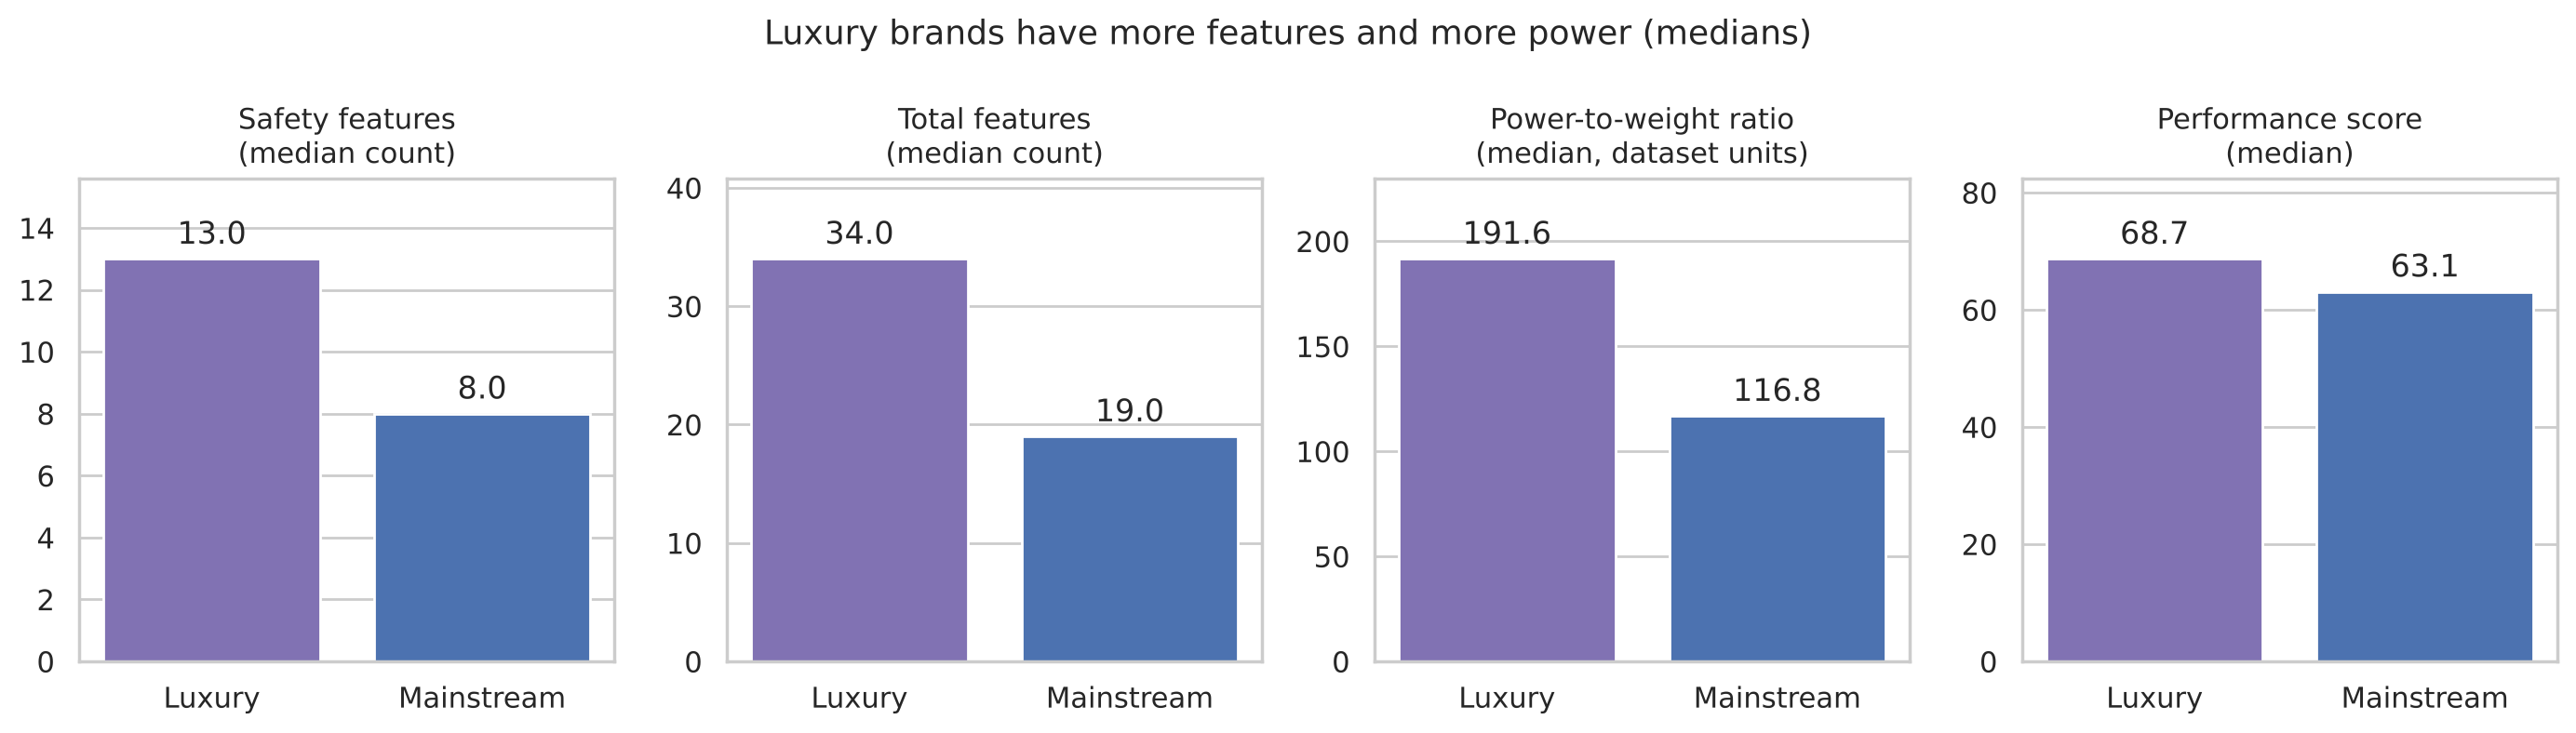

In [5]:
panels = [
    ("safety_feature_count", "Safety features\n(median count)"),
    ("total_feature_count", "Total features\n(median count)"),
    ("power_to_weight_ratio", "Power-to-weight ratio\n(median, dataset units)"),
    ("performance_score", "Performance score\n(median)"),
]
colors = {"Luxury": "#8172B3", "Mainstream": "#4C72B0"}

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (column, label) in zip(axes, panels):
    medians = df.groupby("brand_group")[column].median()
    bars = ax.bar(medians.index, medians.values,
                  color=[colors[g] for g in medians.index])
    ax.bar_label(bars, fmt="%.1f", padding=3)
    ax.set_title(label, fontsize=11)
    ax.set_ylim(0, medians.max() * 1.2)
    ax.grid(axis="x", visible=False)

fig.suptitle("Luxury brands have more features and more power (medians)", fontsize=13)
plt.tight_layout()
plt.savefig(figure_folder / "04_group_features.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see:** The four luxury brands have a median of **13** safety features and **34** total features, compared with **8** and **19** for mainstream brands. Their median power-to-weight ratio is about **192** compared with **117**, and their median performance score is slightly higher (**68.7** vs. **63.1**).

So part of the brand price gap could come from luxury vehicles simply having more features and more power. The next section checks whether the gap remains when we compare vehicles with similar power.

## 4. Does the gap remain for vehicles with similar power?
Power-to-weight ratio has one of the strongest correlations with price (about 0.64 in Notebook 01). We split the vehicles with known prices into four equal-sized groups (quartiles) by power-to-weight ratio. Inside each quartile, vehicles have similar power-to-weight ratios, so we can compare luxury and mainstream prices more fairly.

In [6]:
priced = df.dropna(subset=["original_price"]).copy()

priced["power_quartile"], quartile_edges = pd.qcut(
    priced["power_to_weight_ratio"], 4,
    labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"], retbins=True
)
print("Power-to-weight cut points:", np.round(quartile_edges, 1))

quartile_prices = priced.groupby(["power_quartile", "brand_group"], observed=True)[
    "original_price"].agg(vehicles="count", median_price="median").unstack()

quartile_prices["luxury_vs_mainstream"] = (
    quartile_prices[("median_price", "Luxury")] /
    quartile_prices[("median_price", "Mainstream")]
)
quartile_prices.round(2)

Power-to-weight cut points: [  31.6   94.2  127.1  174.5 1118.5]


vehicles            median_price             \
brand_group      Luxury Mainstream       Luxury Mainstream   
power_quartile                                               
Q1 (lowest)         791      23959     37506.23   26288.39   
Q2                 2252      22498     43049.76   30053.82   
Q3                 4930      19820     49965.74   34184.61   
Q4 (highest)      11430      13320     72915.95   39878.32   

               luxury_vs_mainstream  
brand_group                          
power_quartile                       
Q1 (lowest)                    1.43  
Q2                             1.43  
Q3                             1.46  
Q4 (highest)                   1.83

### Visualization 2: Median price within each power-to-weight quartile
Bars show median original price. The labels show the number of vehicles behind each bar, so small groups are easy to spot.

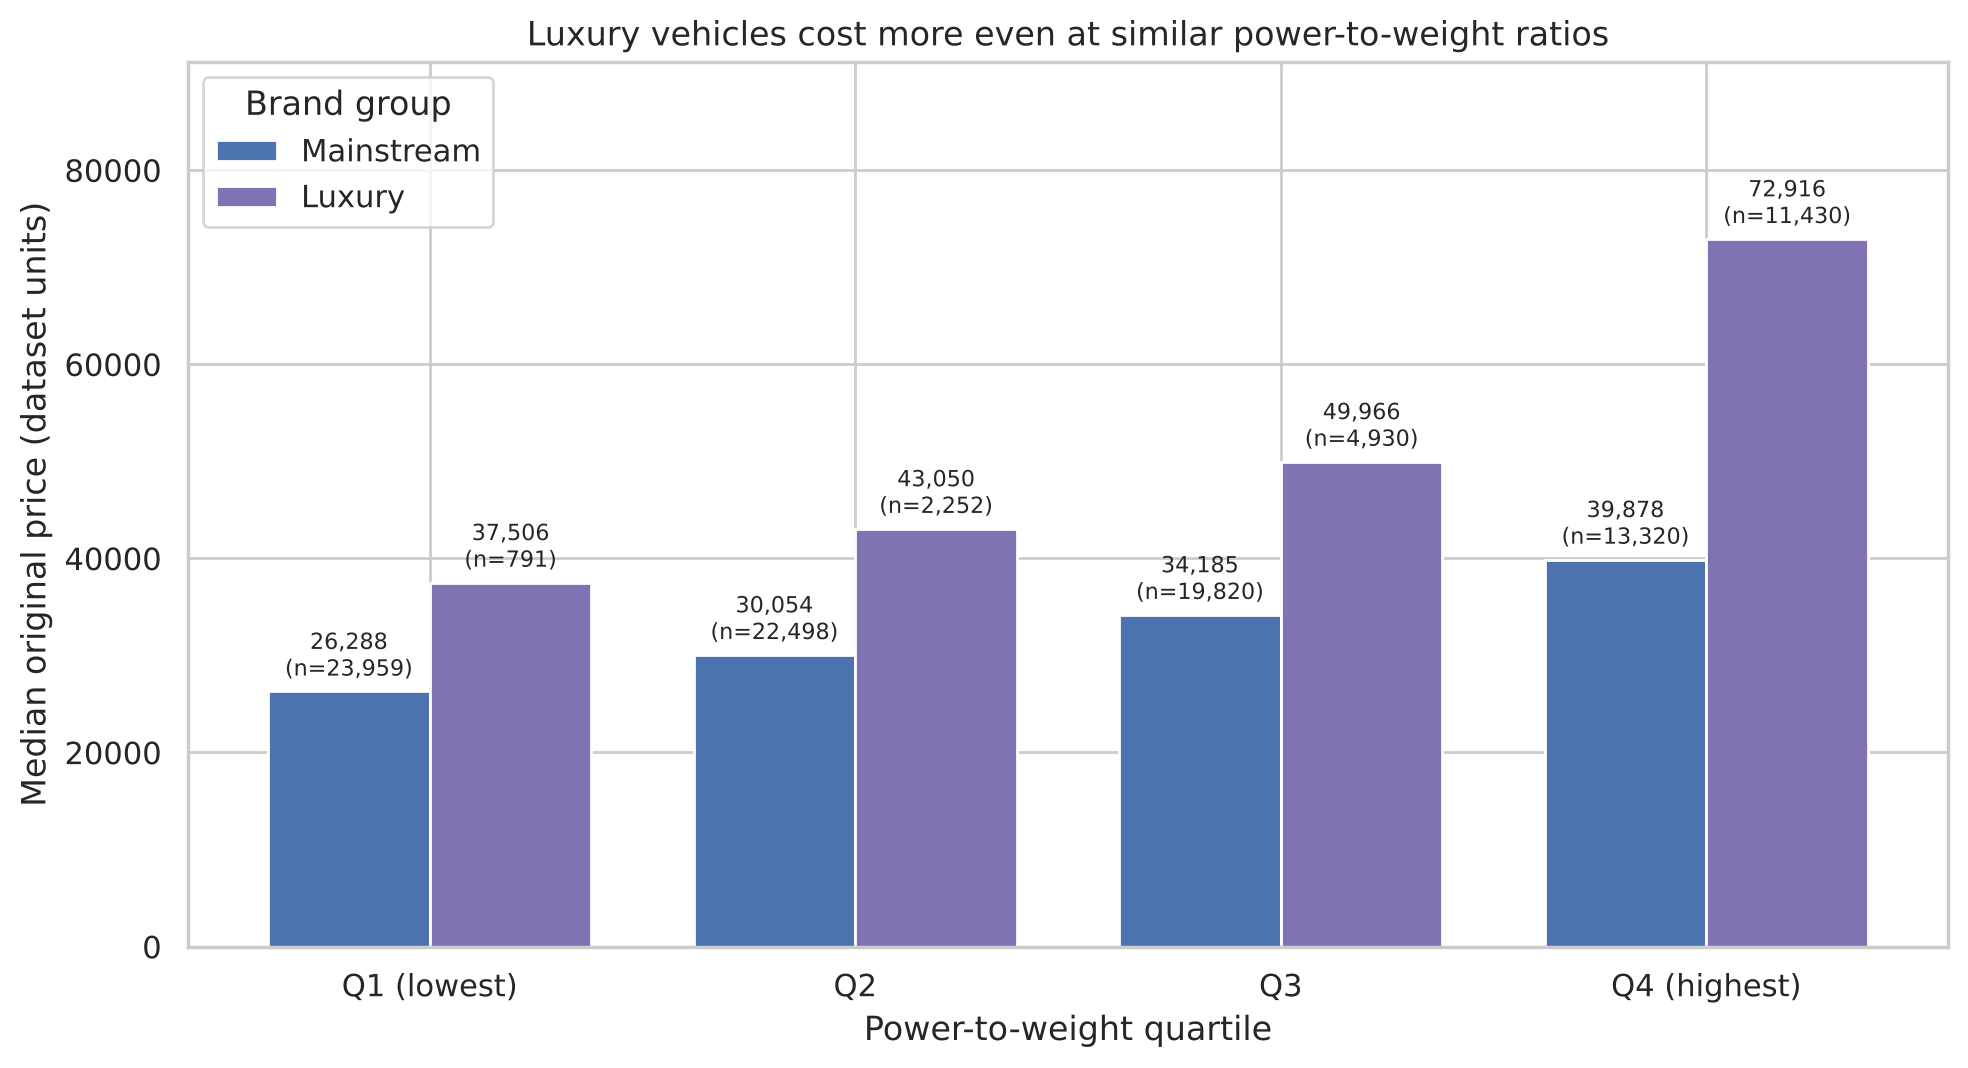

In [7]:
plot_table = quartile_prices["median_price"]
count_table = quartile_prices["vehicles"]

x = np.arange(len(plot_table))
width = 0.38
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, group in enumerate(["Mainstream", "Luxury"]):
    bars = ax.bar(x + (i - 0.5) * width, plot_table[group], width,
                  label=group, color=colors[group])
    labels = [f"{price:,.0f}\n(n={n:,})"
              for price, n in zip(plot_table[group], count_table[group])]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(plot_table.index)
ax.set_xlabel("Power-to-weight quartile")
ax.set_ylabel("Median original price (dataset units)")
ax.set_title("Luxury vehicles cost more even at similar power-to-weight ratios")
ax.set_ylim(0, plot_table.max().max() * 1.25)
ax.legend(title="Brand group")
plt.tight_layout()
plt.savefig(figure_folder / "04_price_by_power_quartile.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see:** In every quartile, the luxury median is higher. Luxury vehicles cost about **1.43 times** the mainstream median in the two lowest quartiles and about **1.83 times** in the highest. Prices rise with power in both groups, but power alone does not close the gap.

The lowest quartile contains only **791** luxury vehicles compared with **23,959** mainstream vehicles. Most luxury vehicles are in the top quartile, which is another reminder that the two groups have very different mixes of vehicles.

### Robustness check: SUVs only
Body type could still differ inside each quartile. We repeat the comparison for SUVs, the most common body type.

In [8]:
suvs = priced[priced["body_type"] == "SUV"]
suv_prices = suvs.groupby(["power_quartile", "brand_group"], observed=True)[
    "original_price"].agg(vehicles="count", median_price="median").unstack()
suv_prices["luxury_vs_mainstream"] = (
    suv_prices[("median_price", "Luxury")] / suv_prices[("median_price", "Mainstream")]
)
suv_prices.round(2)

vehicles            median_price             \
brand_group      Luxury Mainstream       Luxury Mainstream   
power_quartile                                               
Q1 (lowest)         404       7352     39410.57   31186.16   
Q2                 1116       8872     47258.40   32956.79   
Q3                 2197       8488     57468.50   36500.90   
Q4 (highest)       3525       4207     73096.97   43117.85   

               luxury_vs_mainstream  
brand_group                          
power_quartile                       
Q1 (lowest)                    1.26  
Q2                             1.43  
Q3                             1.57  
Q4 (highest)                   1.70

**What we see:** Among SUVs, luxury vehicles still cost about **1.26 to 1.70 times** the mainstream median within the same power quartile. The gap is smaller in the lowest quartile, where there are only **404** luxury SUVs.

## 5. Is the safety-feature relationship a brand effect?
Notebook 02 found that safety-feature count has a correlation of about **0.49** with price. Here we check whether that relationship also holds *inside* each brand group. If it is much weaker inside the groups, the overall correlation mostly reflects the fact that luxury brands have both more safety features and higher prices.

We only plot safety-feature counts with at least 30 priced vehicles in a group, so that medians are not based on a handful of cars.

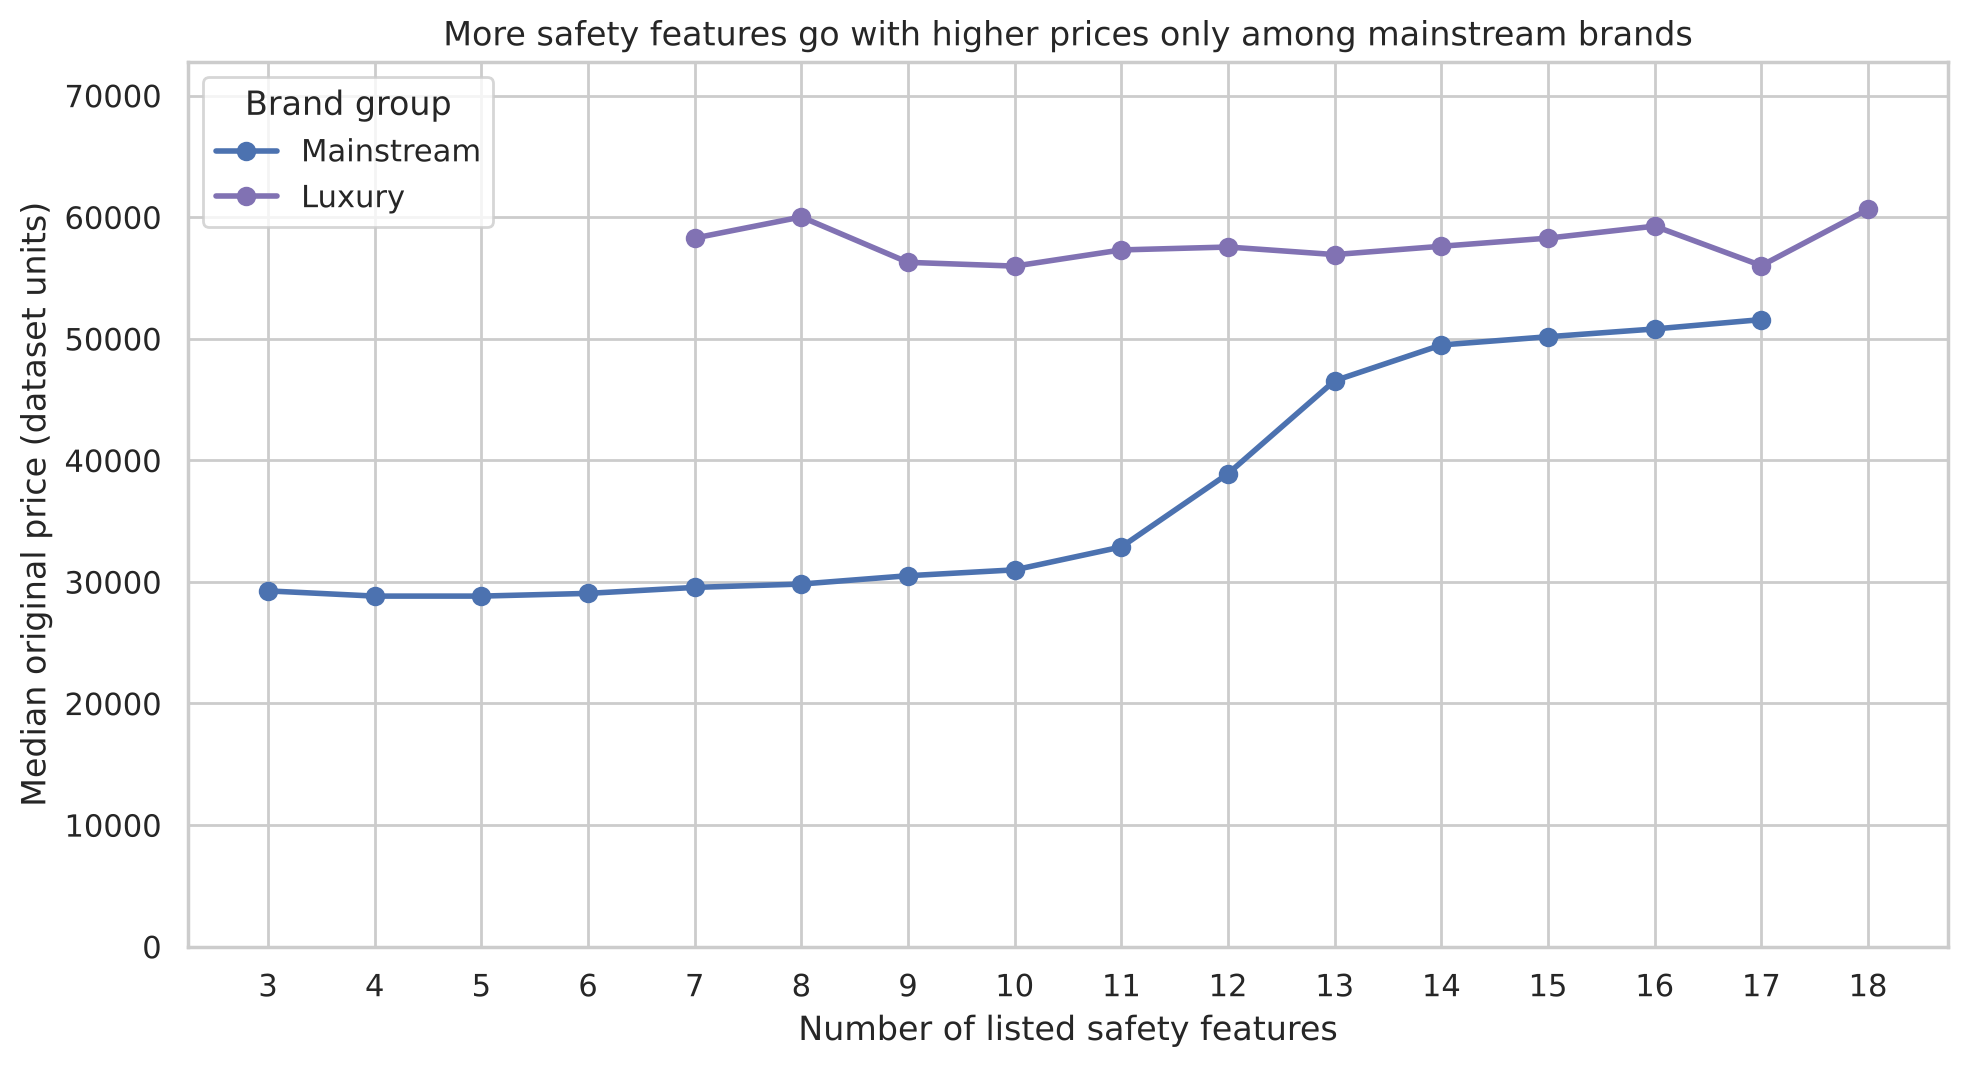

In [9]:
safety_prices = priced.groupby(["brand_group", "safety_feature_count"])[
    "original_price"].agg(vehicles="count", median_price="median").reset_index()
safety_plot = safety_prices[safety_prices["vehicles"] >= 30]

fig, ax = plt.subplots(figsize=(10, 5.5))
for group in ["Mainstream", "Luxury"]:
    rows = safety_plot[safety_plot["brand_group"] == group]
    ax.plot(rows["safety_feature_count"], rows["median_price"], marker="o",
            linewidth=2, label=group, color=colors[group])

ax.set_xlabel("Number of listed safety features")
ax.set_ylabel("Median original price (dataset units)")
ax.set_title("More safety features go with higher prices only among mainstream brands")
ax.set_ylim(0, safety_plot["median_price"].max() * 1.2)
ax.set_xticks(range(int(safety_plot["safety_feature_count"].min()),
                    int(safety_plot["safety_feature_count"].max()) + 1))
ax.legend(title="Brand group")
plt.tight_layout()
plt.savefig(figure_folder / "04_safety_by_group.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
characteristics = ["safety_feature_count", "total_feature_count",
                   "power_to_weight_ratio", "performance_score"]
rows = []
for column in characteristics:
    rows.append({
        "characteristic": column,
        "all vehicles": df["original_price"].corr(df[column]),
        "luxury only": df.loc[df["brand_group"] == "Luxury", "original_price"].corr(
            df.loc[df["brand_group"] == "Luxury", column]),
        "mainstream only": df.loc[df["brand_group"] == "Mainstream", "original_price"].corr(
            df.loc[df["brand_group"] == "Mainstream", column]),
    })
within_group = pd.DataFrame(rows).set_index("characteristic")
within_group.round(3)

,all vehicles,luxury only,mainstream only
characteristic,,,
safety_feature_count,0.488,0.003,0.284
total_feature_count,0.558,-0.009,0.344
power_to_weight_ratio,0.638,0.521,0.558
performance_score,0.358,0.320,0.285


**What we see:** Across all vehicles, safety-feature count has a correlation of **0.488** with price. Inside the luxury group it is **0.003**, essentially zero: luxury medians stay between about 56,000 and 61,000 whatever the count. Inside the mainstream group it is **0.284**, and median prices rise from about 29,000 to about 51,000 as the count increases.

Total feature count shows the same pattern (**0.558** overall, **−0.009** for luxury, **0.344** for mainstream). Power-to-weight ratio behaves differently: its correlation stays similar inside both groups (**0.521** and **0.558**), so power is related to price within each group as well as between them.

This is an example of why a single overall correlation can be misleading: much of the overall safety-feature relationship comes from comparing luxury brands with mainstream brands, not from safety features raising prices within a brand group.

## 6. How was this dataset created?
While checking these patterns we found several signs that the dataset is **synthetic (computer-generated) rather than collected from real sales**. This matters for how far our conclusions can go.

In [11]:
# 1. Does every model appear in every model year?
model_years = df.groupby(["make", "model"])["model_year"].agg(["min", "max", "nunique"])
print("Models:", len(model_years))
print("Models appearing in all 16 model years (2011-2026):",
      (model_years["nunique"] == 16).sum())

# 2. Example: the Hyundai Ioniq 5 was launched in 2021
ioniq = df[df["model"] == "Ioniq 5"]
print("\nIoniq 5 records:", len(ioniq),
      "| records with model year before 2021:", (ioniq["model_year"] < 2021).sum())

# 3. Brand-specific trim names appearing on other brands
for trim in ["M Sport", "AMG"]:
    has_trim = df["model_variant"].fillna("").str.contains(trim)
    print(f"\nBrands with a '{trim}' variant:", df.loc[has_trim, "make"].nunique(),
          "of", df["make"].nunique())

# 4. How MSRP relates to original price
gap_percent = (df["msrp"] / df["original_price"] - 1) * 100
print("\nMSRP above original price: min %.2f%%, max %.2f%%" % (gap_percent.min(), gap_percent.max()))
print("Share of records in each 1-point band (0-1%, 1-2%, ...):")
print(pd.cut(gap_percent, [0, 1, 2, 3, 4, 5], include_lowest=True)
        .value_counts(normalize=True).sort_index().round(3))

Models: 129
Models appearing in all 16 model years (2011-2026): 129

Ioniq 5 records: 739 | records with model year before 2021: 317

Brands with a 'M Sport' variant: 13 of 13

Brands with a 'AMG' variant: 13 of 13

MSRP above original price: min 0.00%, max 5.00%
Share of records in each 1-point band (0-1%, 1-2%, ...):
(-0.001, 1.0]    0.200
(1.0, 2.0]       0.200
(2.0, 3.0]       0.197
(3.0, 4.0]       0.204
(4.0, 5.0]       0.199
Name: proportion, dtype: float64


**What we see:**
- Every model appears in every model year from 2011 to 2026, including the Hyundai Ioniq 5, which did not exist before 2021.
- Trim names that belong to one brand, such as BMW's "M Sport" and Mercedes-Benz's "AMG", appear on all 13 brands.
- MSRP is always 0–5% above original price, and the records are spread almost exactly evenly across that range (about 20% in each 1-point band). Real price data would not look this uniform.
- Notebook 01 found that median price is almost identical at every vehicle age, which is also unusual for real vehicles.

Together these suggest the values were generated by rules and random numbers. Our findings therefore describe **how prices are related to brands and features in this dataset**. They should not be read as evidence about the real car market.

## 7. Summary
- **Luxury brands come with more.** Their median vehicles have 13 safety features vs. 8, 34 total features vs. 19, and a power-to-weight ratio of about 192 vs. 117.
- **The gap remains for similar power.** Within the same power-to-weight quartile, luxury vehicles cost 1.43–1.83 times the mainstream median (1.26–1.70 times among SUVs).
- **Safety features are mainly a brand difference.** The 0.488 overall correlation drops to 0.003 inside the luxury group and 0.284 inside the mainstream group.
- **Answer to our research question (for this dataset):** Higher-priced brands carry more features and more power, which accounts for part of the difference, but a large brand gap remains among vehicles with similar power and the same body type.

### Limitations
- The dataset appears to be synthetic, so results describe the dataset, not the real market.
- The luxury/mainstream grouping is our own choice.
- Quartiles still contain a range of power-to-weight values, and vehicles can differ in other ways (model, equipment, age).
- Safety-feature count is a count of listed features, not a crash-test rating.
- Correlation and group differences do not establish causation.